<a href="https://colab.research.google.com/github/andreapenacastro/Math-Stats_ML/blob/LAB3/Lab3C_SVM_from_scratch_Andrea_Pe%C3%B1acastro.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 3C — Support Vector Machines, from scratch (STUDENT)
**Mathematics & Statistics for Machine Learning — Albert School, MSc 1 (MSA-DATI07-04)**

In this lab you rebuild, step by step, everything we did in Lecture 3C on SVMs:

| Part | What you do | Lecture slides |
|---|---|---|
| 1 | Geometry: distance to a border, width of the street | Geometry 1–3 |
| 2 | The hard-margin SVM on 4 points: support vectors, width | Exercise 3C.1 |
| 3 | The hinge loss, and how it differs from the logistic loss | Hinge loss, 3 cases |
| 4 | The soft margin on the 7-point 1-D example: cost $J(w,b)$, role of $C$ | 1-D example |
| 5 | Training an SVM yourself with **sub-gradient descent** | Hinge route |
| 6 | Support vectors and the three kinds of points ($\alpha_i$) | Soft-margin dual |
| 7 | Kernels: the feature map, the kernel trick, an RBF prediction by hand | Kernels |
| 8 | A real data set: breast cancer, scaling, tuning $C$ and $\gamma$ | SVMs in practice |

**How to work.** Run the cells in order. Cells marked `# TODO` are yours. After each TODO a **checkpoint** cell prints what you should get.

Labels are always $y_i \in \{-1, +1\}$ and the score is $f(x) = w^\top x + b$.

In [1]:
# Setup (everything is pre-installed on Colab)
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.datasets import load_breast_cancer, make_moons, make_circles
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
np.set_printoptions(precision=3, suppress=True)
BLUE, ORANGE, NAVY, SKY, RED = "#3333AB", "#E67E22", "#212447", "#59ADDC", "#C8323C"
print("ready")

ready


## Part 1 — Geometry of a border

For a border $w^\top x + b = 0$:

* $w$ is perpendicular to the border;
* the (signed) distance of a point $x$ to the border is $\delta = \dfrac{w^\top x + b}{\lVert w \rVert}$;
* with the canonical scaling (closest points have $y_i f(x_i) = 1$), the street has width $\dfrac{2}{\lVert w\rVert}$.

**Task 1.1.** Write `distance(w, b, x)` and `street_width(w)`.

In [2]:
def distance(w, b, x):
    # signed distance from x to the border w.x + b = 0
    return (np.dot(w, x) + b) / np.linalg.norm(w)

def street_width(w):
    return 2.0 / np.linalg.norm(w)

In [3]:
# Checkpoint (lecture example: border 3x1 + 4x2 - 12 = 0, point (4,4))
print("distance of (4,4):", distance(np.array([3., 4.]), -12., np.array([4., 4.])), "  expected 3.2")
print("width for w=(3,4):", street_width(np.array([3., 4.])), "  expected 0.4")
print("width for w=(0.6,0.8):", street_width(np.array([0.6, 0.8])), "  expected 2.0")

distance of (4,4): 3.2   expected 3.2
width for w=(3,4): 0.4   expected 0.4
width for w=(0.6,0.8): 2.0   expected 2.0


**Task 1.2 (question).** $(w,b)=((3,4),-12)$ and $((6,8),-24)$ give the same border. What happens to the distance computed by `distance`? What happens to $f(x)$? Why do we need a convention to fix the scale?

In [6]:
# Compute f(x) and distance(...) for both (w, b) and comment
x = np.array([4., 4.])

w1, b1 = np.array([3., 4.]), -12.0
w2, b2 = np.array([6., 8.]), -24.0

f1 = np.dot(w1, x) + b1
f2 = np.dot(w2, x) + b2

d1 = distance(w1, b1, x)
d2 = distance(w2, b2, x)

print(f"For w=(3,4), b=-12: f(x) = {f1:.1f}, distance = {d1:.1f}")
print(f"For w=(6,8), b=-24: f(x) = {f2:.1f}, distance = {d2:.1f}")

print("""
Both sets of parameters define the exact same line (border) where f(x) = 0.
However, doubling the parameters doubles the decision score f(x), while leaving
the actual physical distance to the border unchanged. We need a scale convention
(like requiring the margin/closest points to have y_i * f(x_i) = 1) to make the
optimization problem well-defined and find a unique solution.
""")

For w=(3,4), b=-12: f(x) = 16.0, distance = 3.2
For w=(6,8), b=-24: f(x) = 32.0, distance = 3.2

Both sets of parameters define the exact same line (border) where f(x) = 0.
However, doubling the parameters doubles the decision score f(x), while leaving 
the actual physical distance to the border unchanged. We need a scale convention 
(like requiring the margin/closest points to have y_i * f(x_i) = 1) to make the 
optimization problem well-defined and find a unique solution.



## Part 2 — The hard-margin SVM on 4 points (Exercise 3C.1)

Repay ($+1$): $(2,2)$, $(3,2)$. Default ($-1$): $(1,1)$, $(0,1)$. The solution is $w=(1,1)$, $b=-3$.

**Task 2.1.** Compute $y_i f(x_i)$ for the 4 points. Which ones are support vectors ($y_if=1$)? Compute the width.

In [9]:
X4 = np.array([[2, 2], [3, 2], [1, 1], [0, 1]], float)
y4 = np.array([1, 1, -1, -1], float)
w, b = np.array([1., 1.]), -3.

margins = y4 * (X4 @ w + b)

print("y*f:", margins)
print("support :", X4[np.isclose(margins,1.0)])
print("width :", street_width(w))

y*f: [1. 2. 1. 2.]
support : [[2. 2.]
 [1. 1.]]
width : 1.414213562373095


In [10]:
# Checkpoint: y*f = [1, 2, 1, 2], support vectors (2,2) and (1,1), width 1.414
svc = SVC(kernel="linear", C=1e6).fit(X4, y4)       # sklearn's answer, for comparison
print("sklearn w =", svc.coef_[0], " b =", svc.intercept_[0], " support vectors:\n", svc.support_vectors_)

sklearn w = [1. 1.]  b = -3.0  support vectors:
 [[1. 1.]
 [2. 2.]]


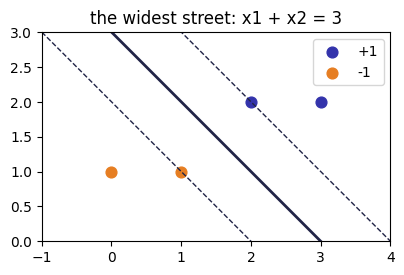

In [11]:
def plot_street(ax, X, y, w, b, title=""):
    gx = np.linspace(X[:, 0].min() - 1, X[:, 0].max() + 1, 100)
    for off, st in [(0, "-"), (1, "--"), (-1, "--")]:
        ax.plot(gx, (off - b - w[0] * gx) / w[1], color=NAVY, ls=st, lw=2 if off == 0 else 1)
    ax.scatter(X[y > 0, 0], X[y > 0, 1], color=BLUE, s=60, label="+1")
    ax.scatter(X[y < 0, 0], X[y < 0, 1], color=ORANGE, s=60, label="-1")
    ax.set_aspect("equal"); ax.set_title(title); ax.legend()
    ax.set_xlim(X[:, 0].min() - 1, X[:, 0].max() + 1); ax.set_ylim(X[:, 1].min() - 1, X[:, 1].max() + 1)

fig, ax = plt.subplots(figsize=(4.5, 4))
plot_street(ax, X4, y4, np.array([1., 1.]), -3., "the widest street: x1 + x2 = 3")
plt.show()

## Part 3 — The hinge loss

For one point with $z = y\,f(x)$:
$$\ell(z) = \max(0,\ 1 - z).$$
Three cases: $z\ge 1$ (safe, loss 0) · $0<z<1$ (inside the street) · $z<0$ (wrong side, loss $>1$).

**Task 3.1.** Write `hinge(z)` and `logistic(z)` $=\log_2(1+e^{-z})$, then plot both on $z\in[-2.5,3]$.

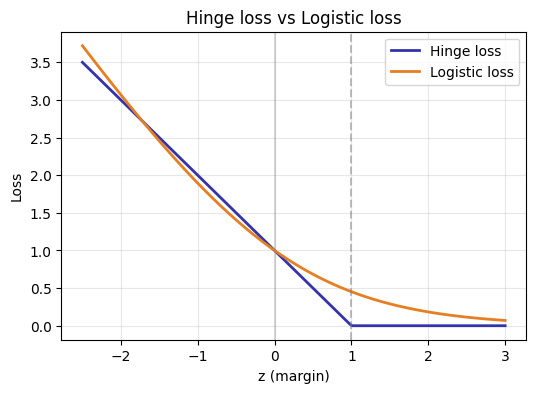

In [12]:
def hinge(z):
    return np.maximum(0.0, 1.0 - z)

def logistic(z):
    return np.log2(1.0 + np.exp(-z))

# Plot hinge(z) and logistic(z) for z in [-2.5, 3]
z_vals = np.linspace(-2.5, 3.0, 200)
plt.figure(figsize=(6, 4))
plt.plot(z_vals, hinge(z_vals), label="Hinge loss", color=BLUE, lw=2)
plt.plot(z_vals, logistic(z_vals), label="Logistic loss", color=ORANGE, lw=2)
plt.axvline(x=1.0, color="gray", linestyle="--", alpha=0.5)
plt.axvline(x=0.0, color="gray", linestyle="-", alpha=0.3)
plt.xlabel("z (margin)")
plt.ylabel("Loss")
plt.title("Hinge loss vs Logistic loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [13]:
# Checkpoint: the hinge is exactly 0 for z >= 1, the logistic loss never is
for zz in [-1, 0, 0.5, 1, 2, 3, 5]:
    print(f"z={zz:>4}: hinge={hinge(zz):.3f}  logistic={logistic(zz):.3f}")
# expected hinge: 2, 1, 0.5, 0, 0, 0, 0   logistic: 1.895, 1, 0.684, 0.452, 0.183, 0.070, 0.010

z=  -1: hinge=2.000  logistic=1.895
z=   0: hinge=1.000  logistic=1.000
z= 0.5: hinge=0.500  logistic=0.684
z=   1: hinge=0.000  logistic=0.452
z=   2: hinge=0.000  logistic=0.183
z=   3: hinge=0.000  logistic=0.070
z=   5: hinge=0.000  logistic=0.010


**Task 3.2 (slacks).** The slack of a point is the smallest $\xi\ge0$ with $y f \ge 1-\xi$, i.e. $\xi = \max(0, 1 - yf)$ — the hinge. Compute the slacks of three class-$(+1)$ points with $yf = 1.5,\ 0.6,\ -0.3$. Check that $\sum\xi$ is at least the number of misclassified points.

In [14]:
yf = np.array([1.5, 0.6, -0.3])
xi = hinge(yf)
print("slacks:", xi, "  sum:", xi.sum(), "  errors:", np.sum(yf < 0))

slacks: [0.  0.4 1.3]   sum: 1.7000000000000002   errors: 1


In [ ]:
# Checkpoint: slacks [0, 0.4, 1.3], sum 1.7 >= 1 error

## Part 4 — The soft margin on the 1-D example

Seven clients on a line; $x=1.5$ is an outlier labelled $-1$:

| $x$ | −3 | −2 | −1 | 1 | 2 | 3 | 1.5 |
|---|---|---|---|---|---|---|---|
| $y$ | −1 | −1 | −1 | +1 | +1 | +1 | −1 |

Soft-margin cost:
$$J(w,b) = \tfrac12 w^2 + C\sum_i \max\big(0,\ 1 - y_i(wx_i+b)\big).$$

**Task 4.1.** Write `J(w, b, C)`. Evaluate the two solutions of the lecture: $(0.4,-0.2)$ for $C=0.1$ and $(2/3,-1/3)$ for $C=10$.

In [15]:
x1 = np.array([-3, -2, -1, 1, 2, 3, 1.5])
y1 = np.array([-1, -1, -1, 1, 1, 1, -1])

def J(w, b, C, x=x1, y=y1):
    return 0.5 * (w ** 2) + C * hinge(y * (w * x + b)).sum()

for (w_, b_, C) in [(0.4, -0.2, 0.1), (2/3, -1/3, 10)]:
    h = hinge(y1 * (w_ * x1 + b_))
    print(f"C={C:>4}: w={w_:.3f} b={b_:.3f}  hinges={h.round(3)}  sum={h.sum():.3f}  J={J(w_, b_, C):.3f}  width={2/w_:.1f}")

C= 0.1: w=0.400 b=-0.200  hinges=[0.  0.  0.4 0.8 0.4 0.  1.4]  sum=3.000  J=0.380  width=5.0
C=  10: w=0.667 b=-0.333  hinges=[0.    0.    0.    0.667 0.    0.    1.667]  sum=2.333  J=23.556  width=3.0


In [ ]:
# Checkpoint: C=0.1 -> hinges [0 0 0.4 0.8 0.4 0 1.4], sum 3.0, J 0.38, width 5
#             C=10  -> sum 2.333, J 23.556, width 3

**Task 4.2 (no solver!).** Find the minimum of $J$ by brute force: evaluate $J$ on a grid of $(w,b)$ values and keep the smallest. Do it for $C=0.1$ and $C=10$, and compare with `SVC(kernel="linear", C=C)`.

In [16]:
W_grid = np.linspace(0, 1.5, 301)
B_grid = np.linspace(-1.5, 1.5, 301)
for C in [0.1, 10]:
    # Evaluate J on the grid
    best_J = float('inf')
    best_w, best_b = None, None
    for w_val in W_grid:
        for b_val in B_grid:
            cost = J(w_val, b_val, C)
            if cost < best_J:
                best_J = cost
                best_w, best_b = w_val, b_val

    # Compare with sklearn's SVC
    X1_col = x1[:, None]
    svc = SVC(kernel="linear", C=C).fit(X1_col, y1)
    svc_w = svc.coef_[0, 0]
    svc_b = svc.intercept_[0]

    print(f"C = {C}:")
    print(f"  Brute-force: w = {best_w:.3f}, b = {best_b:.3f}, J = {best_J:.3f}")
    print(f"  scikit-learn: w = {svc_w:.3f}, b = {svc_b:.3f}, J = {J(svc_w, svc_b, C):.3f}")

C = 0.1:
  Brute-force: w = 0.400, b = -0.200, J = 0.380
  scikit-learn: w = 0.400, b = -0.200, J = 0.380
C = 10:
  Brute-force: w = 0.670, b = -0.340, J = 23.574
  scikit-learn: w = 0.667, b = -0.333, J = 23.556


**Task 4.3.** Plot the street of both solutions on the line, then plot the street width $2/w$ and the total hinge as functions of $C$ (log scale, $C$ from $0.01$ to $100$). Comment: does a large $C$ give zero violations here? What happens for $C=0.01$?

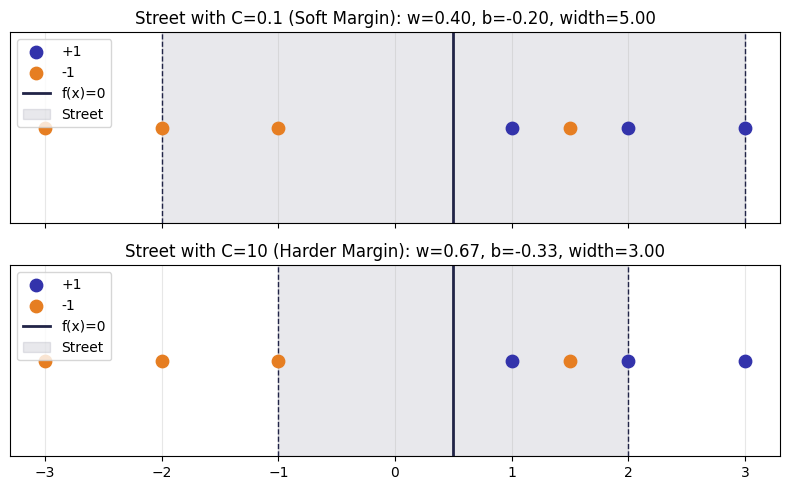

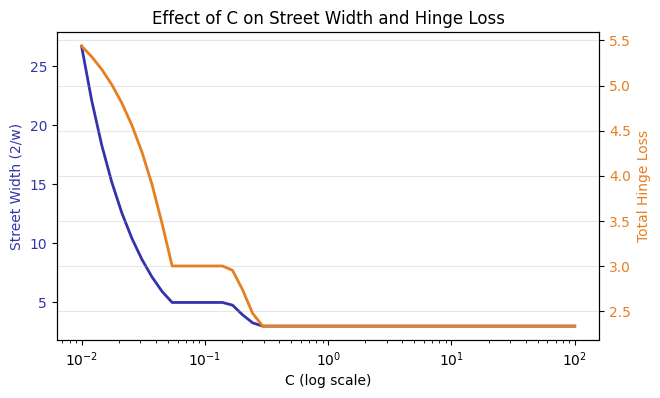

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC

# (a) Draw both streets on the 1-D line
fig, axes = plt.subplots(2, 1, figsize=(8, 5), sharex=True)
for ax, C_val, title in zip(axes, [0.1, 10], ["Street with C=0.1 (Soft Margin)", "Street with C=10 (Harder Margin)"]):
    svc = SVC(kernel="linear", C=C_val).fit(x1[:, None], y1)
    w_val = svc.coef_[0, 0]
    b_val = svc.intercept_[0]

    # Plot points
    ax.scatter(x1[y1 > 0], np.zeros_like(x1[y1 > 0]), color=BLUE, s=80, label="+1", zorder=3)
    ax.scatter(x1[y1 < 0], np.zeros_like(x1[y1 < 0]), color=ORANGE, s=80, label="-1", zorder=3)

    # Plot decision boundary (f(x)=0) and street boundaries (f(x)=1, f(x)=-1)
    border = -b_val / w_val
    street_pos = (1.0 - b_val) / w_val
    street_neg = (-1.0 - b_val) / w_val

    ax.axvline(border, color=NAVY, linestyle="-", lw=2, label="f(x)=0")
    ax.axvline(street_pos, color=NAVY, linestyle="--", lw=1)
    ax.axvline(street_neg, color=NAVY, linestyle="--", lw=1)
    ax.axvspan(min(street_pos, street_neg), max(street_pos, street_neg), color=NAVY, alpha=0.1, label="Street")

    ax.set_title(f"{title}: w={w_val:.2f}, b={b_val:.2f}, width={2/w_val:.2f}")
    ax.get_yaxis().set_visible(False)
    ax.legend(loc="upper left")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# (b) Loop over Cs, fit SVC, and plot
Cs = np.logspace(-2, 2, 50)
widths = []
hinges_sums = []

for C_val in Cs:
    svc = SVC(kernel="linear", C=C_val).fit(x1[:, None], y1)
    w_val = svc.coef_[0, 0]
    b_val = svc.intercept_[0]
    widths.append(2.0 / w_val)
    hinges_sums.append(hinge(y1 * (w_val * x1 + b_val)).sum())

fig, ax1 = plt.subplots(figsize=(7, 4))

color = BLUE
ax1.set_xlabel("C (log scale)")
ax1.set_ylabel("Street Width (2/w)", color=color)
ax1.semilogx(Cs, widths, color=color, lw=2)
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color = ORANGE
ax2.set_ylabel("Total Hinge Loss", color=color)
ax2.semilogx(Cs, hinges_sums, color=color, lw=2)
ax2.tick_params(axis='y', labelcolor=color)

plt.title("Effect of C on Street Width and Hinge Loss")
plt.grid(True, which="both", alpha=0.3)
plt.show()

## Part 5 — Train the SVM yourself: sub-gradient descent

The cost $J(w,b)=\tfrac12\lVert w\rVert^2 + C\sum_i \max(0, 1-y_i f(x_i))$ has a kink, but away from it:
$$g_w = w - C\!\!\sum_{i:\,y_if_i<1}\!\! y_i x_i,\qquad g_b = -C\!\!\sum_{i:\,y_if_i<1}\!\! y_i .$$
Only the **violators** ($y_if_i<1$) push. Update: $w \leftarrow w-\eta_t g_w$, $b\leftarrow b-\eta_t g_b$ with a shrinking step $\eta_t = \eta_0/\sqrt{t}$.

**Task 5.1.** Write `svm_subgradient(X, y, C, eta0, n_iter)` returning $w$, $b$ and the history of $J$.

In [18]:
def objective(w, b, X, y, C):
    return 0.5 * w @ w + C * hinge(y * (X @ w + b)).sum()

def svm_subgradient(X, y, C=1.0, eta0=0.5, n_iter=5000):
    w, b = np.zeros(X.shape[1]), 0.0
    history = []
    for t in range(1, n_iter + 1):
        f_val = X @ w + b
        viol = (y * f_val < 1.0) # boolean mask of the violators
        g_w = w - C * np.sum(y[viol][:, None] * X[viol], axis=0)
        g_b = -C * np.sum(y[viol])
        eta = eta0 / np.sqrt(t)
        w = w - eta * g_w
        b = b - eta * g_b
        history.append(objective(w, b, X, y, C))
    return w, b, history

**Task 5.2.** Check the first step by hand on the 4 points (lecture): from $w=(0,0)$, $b=0$, $\eta_1=0.5$, $C=1$ you should get $w=(2,1)$, $b=0$. Then run 20 000 iterations: you should approach $w=(1,1)$, $b=-3$.

after 1 step : [2. 1.] 0.0    expected [2, 1], 0
after 20000  : [0.991 0.991] -2.968    expected close to [1, 1], -3


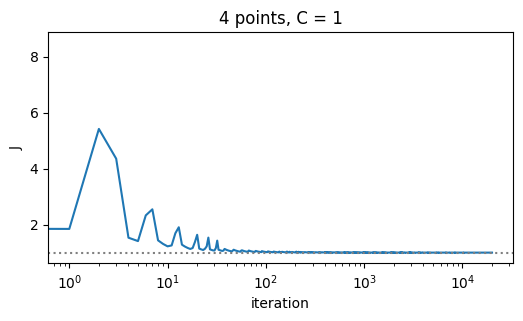

In [19]:
w_1, b_1, _ = svm_subgradient(X4, y4, C=1.0, eta0=0.5, n_iter=1)
print("after 1 step :", w_1, b_1, "   expected [2, 1], 0")
w_, b_, hist = svm_subgradient(X4, y4, C=1.0, eta0=0.5, n_iter=20000)
print("after 20000  :", w_.round(3), round(b_, 3), "   expected close to [1, 1], -3")
plt.figure(figsize=(6, 3)); plt.semilogx(hist); plt.axhline(1, ls=":", color="gray")
plt.xlabel("iteration"); plt.ylabel("J"); plt.title("4 points, C = 1"); plt.show()

**Task 5.3.** Same on the 1-D example with $C=0.1$, $\eta_0=1$: the first step should give $w=1.05$, $b=-0.1$, and the limit $w=0.4$, $b=-0.2$, $J=0.38$.

In [21]:
X1d = x1[:, None].astype(float)
y1d = y1.astype(float)

# One step of subgradient descent
w_1d_1, b_1d_1, _ = svm_subgradient(X1d, y1d, C=0.1, eta0=1.0, n_iter=1)
J_1 = objective(w_1d_1, b_1d_1, X1d, y1d, C=0.1)
print(f"after 1 step : w = {w_1d_1[0]:.3f}, b = {b_1d_1:.3f}, J = {J_1:.3f}   expected w = 1.05, b = -0.1")

# 20,000 steps of subgradient descent
w_1d_opt, b_1d_opt, hist_1d = svm_subgradient(X1d, y1d, C=0.1, eta0=1.0, n_iter=20000)
J_opt = objective(w_1d_opt, b_1d_opt, X1d, y1d, C=0.1)
print(f"after 20000  : w = {w_1d_opt[0]:.3f}, b = {b_1d_opt:.3f}, J = {J_opt:.3f}   expected w = 0.4, b = -0.2, J = 0.380")

after 1 step : w = 1.050, b = -0.100, J = 0.804   expected w = 1.05, b = -0.1
after 20000  : w = 0.399, b = -0.201, J = 0.380   expected w = 0.4, b = -0.2, J = 0.380


## Part 6 — Support vectors and the three kinds of points

scikit-learn solves the dual. For each support vector it stores $\alpha_i y_i$ in `dual_coef_`. Every multiplier satisfies $0\le\alpha_i\le C$:

| $\alpha_i$ | position |
|---|---|
| $0$ | outside the street — ignored |
| $0<\alpha_i<C$ | exactly on a kerb ($y_if=1$) |
| $C$ | inside the street or on the wrong side |

**Task 6.1.** Fit `SVC(kernel="linear", C=10)` on the 1-D data. Recover all $\alpha_i$, classify each point, and check $\sum_i\alpha_iy_i=0$ and $w=\sum_i\alpha_iy_ix_i$.

In [22]:
C = 10
m = SVC(kernel="linear", C=C).fit(X1d, y1d)
alpha = np.zeros(len(x1))

# Fill alpha from m.support_ and m.dual_coef_
# m.dual_coef_ holds y_i * alpha_i for the support vectors
alpha[m.support_] = np.abs(m.dual_coef_[0])

w_recovered = np.sum(alpha * y1 * x1)
b_val = m.intercept_[0]
f_vals = w_recovered * x1 + b_val
margins = y1 * f_vals

print("Point | y_i | x_i | y*f(x) | alpha_i | Kind")
print("-" * 55)
for i in range(len(x1)):
    yf = margins[i]
    al = alpha[i]
    if al == 0:
        kind = "Outside street (ignored)"
    elif np.isclose(al, C):
        kind = "Inside street / Violator (capped at C)"
    else:
        kind = "On the kerb (y*f = 1)"
    print(f"{i:<5} | {y1[i]:>3.0f} | {x1[i]:>3.1f} | {yf:>6.3f} | {al:>7.3f} | {kind}")

print("\nVerifications:")
print(f"Sum of alpha * y: {np.sum(alpha * y1):.6f} (expected: 0)")
print(f"Recovered w     : {w_recovered:.4f} (expected: {m.coef_[0, 0]:.4f})")

Point | y_i | x_i | y*f(x) | alpha_i | Kind
-------------------------------------------------------
0     |  -1 | -3.0 |  2.333 |   0.000 | Outside street (ignored)
1     |  -1 | -2.0 |  1.667 |   0.000 | Outside street (ignored)
2     |  -1 | -1.0 |  1.000 |   1.889 | On the kerb (y*f = 1)
3     |   1 | 1.0 |  0.333 |  10.000 | Inside street / Violator (capped at C)
4     |   1 | 2.0 |  1.000 |   1.889 | On the kerb (y*f = 1)
5     |   1 | 3.0 |  1.667 |   0.000 | Outside street (ignored)
6     |  -1 | 1.5 | -0.667 |  10.000 | Inside street / Violator (capped at C)

Verifications:
Sum of alpha * y: 0.000000 (expected: 0)
Recovered w     : 0.6667 (expected: 0.6667)


In [ ]:
# Checkpoint: x=-1 and x=2 on the kerbs with alpha = 17/9 = 1.889;
#             x=1 and x=1.5 capped at alpha = 10; the other three alpha = 0; w = 0.6667

## Part 7 — Kernels

**Task 7.1 — the kernel trick.** With $\phi(x)=(x_1^2,\ \sqrt2\,x_1x_2,\ x_2^2)$ check that $\phi(x)^\top\phi(z)=(x^\top z)^2$ for $x=(1,2)$, $z=(3,1)$ and for 1000 random pairs.

In [24]:
def phi(x):
    # x is a 2D vector or array-like [x1, x2]
    return np.array([x[0]**2, np.sqrt(2) * x[0] * x[1], x[1]**2])

x = np.array([1., 2.])
zv = np.array([3., 1.])

# Single pair check
phi_x = phi(x)
phi_zv = phi(zv)
left_side = phi_x @ phi_zv
right_side = (x @ zv) ** 2

print(f"Single pair verification:")
print(f"  phi(x) @ phi(z) = {left_side:.3f}")
print(f"  (x @ z)^2       = {right_side:.3f}")
print(f"  Close?          = {np.isclose(left_side, right_side)}\n")

# Verification over 1000 random pairs
np.random.seed(42)
X_rand = np.random.randn(1000, 2)
Z_rand = np.random.randn(1000, 2)

all_close = True
for i in range(1000):
    xi = X_rand[i]
    zi = Z_rand[i]
    if not np.isclose(phi(xi) @ phi(zi), (xi @ zi) ** 2):
        all_close = False
        break

print(f"Verified over 1000 random pairs: {all_close}")

Single pair verification:
  phi(x) @ phi(z) = 25.000
  (x @ z)^2       = 25.000
  Close?          = True

Verified over 1000 random pairs: True


**Task 7.2 — circles.** On `make_circles`, compare (a) a linear SVM on $(x_1,x_2)$, (b) a linear SVM on the single new feature $z=x_1^2+x_2^2$, (c) an RBF SVM. Use 5-fold cross-validation.

(a) Linear SVM on (x1, x2)      : CV Accuracy = 0.4850 +/- 0.0509
(b) Linear SVM on z = x1^2 + x2^2: CV Accuracy = 1.0000 +/- 0.0000
(c) RBF SVM on (x1, x2)          : CV Accuracy = 1.0000 +/- 0.0000


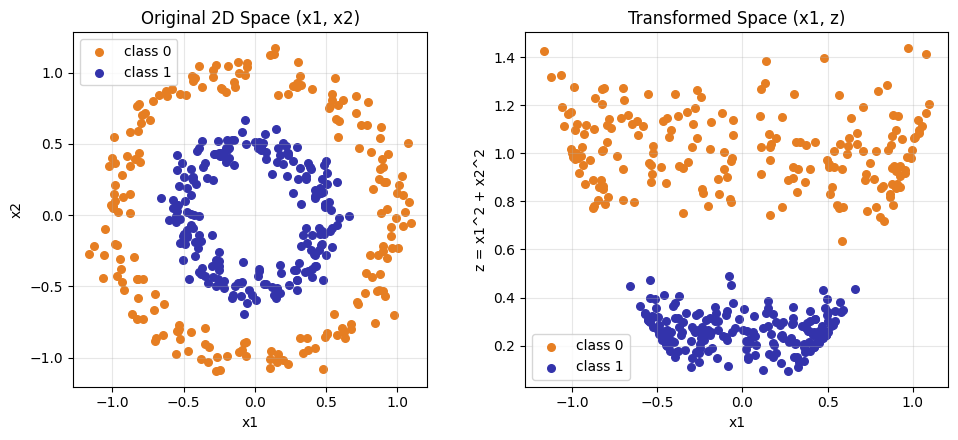

In [25]:
Xc, yc = make_circles(400, noise=0.08, factor=0.5, random_state=0)
zc = (Xc**2).sum(axis=1, keepdims=True)

# 5-fold CV accuracies
clf_a = SVC(kernel="linear")
scores_a = cross_val_score(clf_a, Xc, yc, cv=5)

clf_b = SVC(kernel="linear")
scores_b = cross_val_score(clf_b, zc, yc, cv=5)

clf_c = SVC(kernel="rbf")
scores_c = cross_val_score(clf_c, Xc, yc, cv=5)

print(f"(a) Linear SVM on (x1, x2)      : CV Accuracy = {scores_a.mean():.4f} +/- {scores_a.std():.4f}")
print(f"(b) Linear SVM on z = x1^2 + x2^2: CV Accuracy = {scores_b.mean():.4f} +/- {scores_b.std():.4f}")
print(f"(c) RBF SVM on (x1, x2)          : CV Accuracy = {scores_c.mean():.4f} +/- {scores_c.std():.4f}")

# Plots
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))

# (x1, x2) space
axes[0].scatter(Xc[yc == 0, 0], Xc[yc == 0, 1], color=ORANGE, s=30, label="class 0")
axes[0].scatter(Xc[yc == 1, 0], Xc[yc == 1, 1], color=BLUE, s=30, label="class 1")
axes[0].set_xlabel("x1")
axes[0].set_ylabel("x2")
axes[0].set_title("Original 2D Space (x1, x2)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)
axes[0].set_aspect('equal')

# (x1, z) space
axes[1].scatter(Xc[yc == 0, 0], zc[yc == 0, 0], color=ORANGE, s=30, label="class 0")
axes[1].scatter(Xc[yc == 1, 0], zc[yc == 1, 0], color=BLUE, s=30, label="class 1")
axes[1].set_xlabel("x1")
axes[1].set_ylabel("z = x1^2 + x2^2")
axes[1].set_title("Transformed Space (x1, z)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

**Task 7.3 — an RBF prediction by hand.** For an RBF SVM,
$$f(x)=\sum_{i\in SV}\alpha_iy_i\,K(x_i,x)+b,\qquad K(x,z)=\exp(-\gamma\lVert x-z\rVert^2).$$
Fit `SVC(kernel="rbf", gamma=1, C=1)` on 200 moons. Recompute `decision_function` for 5 new points **yourself** using `support_vectors_`, `dual_coef_` (which holds $\alpha_iy_i$) and `intercept_`.

In [26]:
Xm, ym = make_moons(200, noise=0.25, random_state=0)
rbf = SVC(kernel="rbf", gamma=1.0, C=1.0).fit(Xm, ym)
Xnew = np.array([[0., 0.5], [1., 0.], [-1., 0.5], [2., 0.], [0.5, -0.3]])

def f_by_hand(xnew, model, gamma):
    # Recompute: sum_{i in SV} (alpha_i * y_i) * exp(-gamma * ||x_i - x||^2) + b
    # model.dual_coef_[0] holds alpha_i * y_i
    # model.support_vectors_ holds x_i
    # model.intercept_[0] holds b
    diffs = model.support_vectors_ - xnew
    sq_dists = np.sum(diffs ** 2, axis=1)
    kernel_vals = np.exp(-gamma * sq_dists)
    return np.sum(model.dual_coef_[0] * kernel_vals) + model.intercept_[0]

# Compare f_by_hand with rbf.decision_function for each new point
print("Point            | Hand-computed | sklearn    | Match?")
print("-" * 55)
for x_pt in Xnew:
    val_hand = f_by_hand(x_pt, rbf, gamma=1.0)
    val_sklearn = rbf.decision_function([x_pt])[0]
    match = np.isclose(val_hand, val_sklearn)
    print(f"{str(x_pt):<16} | {val_hand:>13.6f} | {val_sklearn:>10.6f} | {match}")

Point            | Hand-computed | sklearn    | Match?
-------------------------------------------------------
[0.  0.5]        |     -0.082763 |  -0.082763 | True
[1. 0.]          |      0.017309 |   0.017309 | True
[-1.   0.5]      |     -1.660347 |  -1.660347 | True
[2. 0.]          |      1.539621 |   1.539621 | True
[ 0.5 -0.3]      |      1.485392 |   1.485392 | True


**Task 7.4 — the knobs $\gamma$ and $C$.** Draw the decision regions for $\gamma\in\{0.1, 1, 50\}$ ($C=1$). Then grid-search $C,\gamma\in\{0.1,1,10,100\}$ with 5-fold CV.

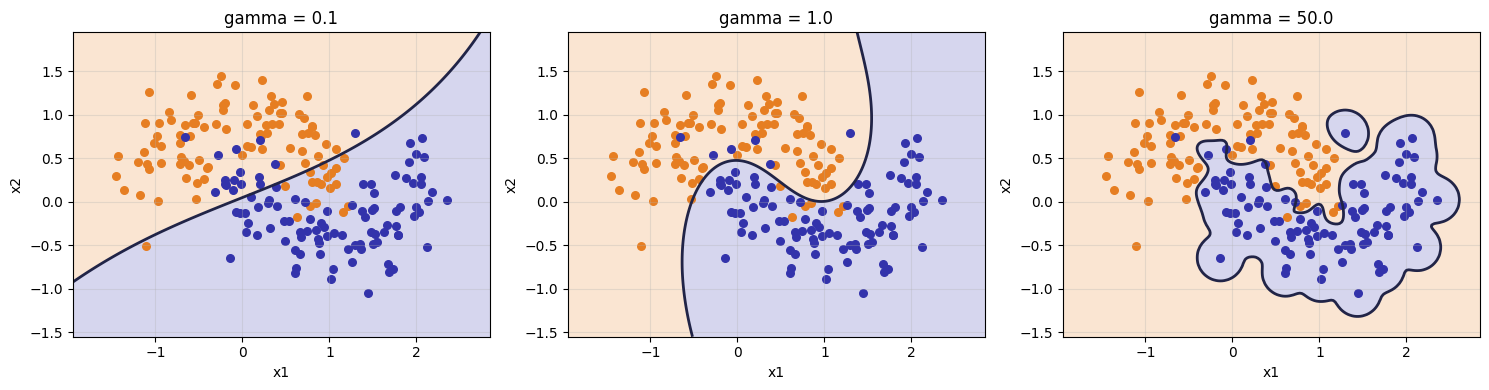

Best Parameters: {'C': 0.1, 'gamma': 10.0}
Best CV Accuracy: 0.9400


In [27]:
# 1. Decision regions for gamma in {0.1, 1, 50} (C=1)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
gammas = [0.1, 1.0, 50.0]

# Create a mesh grid to plot decision boundary contours
x_min, x_max = Xm[:, 0].min() - 0.5, Xm[:, 0].max() + 0.5
y_min, y_max = Xm[:, 1].min() - 0.5, Xm[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))
mesh_points = np.c_[xx.ravel(), yy.ravel()]

for ax, gamma in zip(axes, gammas):
    clf = SVC(kernel="rbf", gamma=gamma, C=1.0).fit(Xm, ym)
    Z = clf.decision_function(mesh_points)
    Z = Z.reshape(xx.shape)

    # Plot filled decision regions
    ax.contourf(xx, yy, Z, levels=[-999, 0, 999], colors=[ORANGE, BLUE], alpha=0.2)
    ax.contour(xx, yy, Z, levels=[0], colors=NAVY, linewidths=2)

    # Plot points
    ax.scatter(Xm[ym == 0, 0], Xm[ym == 0, 1], color=ORANGE, s=30, label="class 0")
    ax.scatter(Xm[ym == 1, 0], Xm[ym == 1, 1], color=BLUE, s=30, label="class 1")
    ax.set_title(f"gamma = {gamma}")
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# 2. GridSearchCV over C and gamma
param_grid = {'C': [0.1, 1.0, 10.0, 100.0], 'gamma': [0.1, 1.0, 10.0, 100.0]}
grid = GridSearchCV(SVC(kernel="rbf"), param_grid, cv=5)
grid.fit(Xm, ym)

print(f"Best Parameters: {grid.best_params_}")
print(f"Best CV Accuracy: {grid.best_score_:.4f}")

## Part 8 — A real data set: breast cancer

569 patients, 30 features, labels $\pm1$.

**Task 8.1.** Train your sub-gradient SVM (`C=1`, a small step, many iterations) on the **standardised** training set and compare objective and test accuracy with `SVC(kernel="linear", C=1)`.

**Task 8.2.** Show why scaling matters: compare an RBF SVM with and without `StandardScaler` (5-fold CV on the training set).

In [30]:
Xb, yb = load_breast_cancer(return_X_y=True)
yb = 2 * yb - 1
Xtr, Xte, ytr, yte = train_test_split(Xb, yb, test_size=0.3, random_state=0, stratify=yb)

# TODO 8.1: standardise (fit the scaler on the TRAINING set only), run svm_subgradient(C=1, eta0=0.01, n_iter=20000) compare objective and test accuracy with SVC(kernel="linear", C=1)

# 1. Scaling the training data
scaler = StandardScaler()
Xtr_scaled = scaler.fit_transform(Xtr)
Xte_scaled = scaler.transform(Xte)

# 2. Running subgradient descent
w_custom, b_custom, hist_custom = svm_subgradient(Xtr_scaled, ytr, C=1.0, eta0=0.01, n_iter=20000)

# 3. Fitting scikit-learn SVC
svc_lin = SVC(kernel="linear", C=1.0).fit(Xtr_scaled, ytr)

# 4. Compute Objectives
obj_custom = objective(w_custom, b_custom, Xtr_scaled, ytr, C=1.0)
w_svc = svc_lin.coef_[0]
b_svc = svc_lin.intercept_[0]
obj_svc = objective(w_svc, b_svc, Xtr_scaled, ytr, C=1.0)

# 5. Compute Test Accuracies
acc_custom = np.mean(np.sign(Xte_scaled @ w_custom + b_custom) == yte)
acc_svc = svc_lin.score(Xte_scaled, yte)

print(f"Custom SVM subgradient: Final Objective = {obj_custom:.3f}, Test Accuracy = {acc_custom:.4%}")
print(f"scikit-learn linear SVC: Final Objective = {obj_svc:.3f}, Test Accuracy = {acc_svc:.4%}")
print()

# TODO 8.2: CV accuracy of SVC(kernel="rbf") with and without StandardScaler (use make_pipeline)

# RBF without scaling
pipe_no_scaling = make_pipeline(SVC(kernel="rbf"))
scores_no_scaling = cross_val_score(pipe_no_scaling, Xtr, ytr, cv=5)

# RBF with scaling
pipe_with_scaling = make_pipeline(StandardScaler(), SVC(kernel="rbf"))
scores_with_scaling = cross_val_score(pipe_with_scaling, Xtr, ytr, cv=5)

print(f"RBF SVM without scaling: Mean CV Accuracy = {scores_no_scaling.mean():.4%} +/- {scores_no_scaling.std():.4%}")
print(f"RBF SVM with scaling:    Mean CV Accuracy = {scores_with_scaling.mean():.4%} +/- {scores_with_scaling.std():.4%}")

Custom SVM subgradient: Final Objective = 14.222, Test Accuracy = 95.3216%
scikit-learn linear SVC: Final Objective = 14.200, Test Accuracy = 95.3216%

RBF SVM without scaling: Mean CV Accuracy = 92.2120% +/- 3.1989%
RBF SVM with scaling:    Mean CV Accuracy = 97.9968% +/- 1.2729%


## Wrap-up questions

### 1. A point has y f(x) = 0.7. Is it misclassified? What is its hinge loss?

Nope, it is actually correctly classified! Because the score has a positive margin (0.7), the model has put it on the correct side of the decision boundary.

However, it is not comfortably safe outside the street. Since it landed inside our margin street (where the boundary lines are at 1 and -1), we still give it a small penalty for being too close. Its hinge loss is:
loss = 1 - 0.7 = 0.3
So it is correctly guessed, but we still pay a 0.3 penalty because it is crowding the boundary!


### 2. In Part 4, why does the total hinge never reach 0, however large C is?

Because the dataset has a permanent outlier (the point x = 1.5 with label -1) that makes the two classes impossible to split perfectly with a straight line. No matter how much we shrink the street or increase C to punish mistakes, that outlier will always end up on the wrong side of the divider, so the hinge loss can never drop all the way to 0.


### 3. In Part 5, why do we use a step size that shrinks with t?

It is like looking for your keys on the floor in the dark. At first, you want to make big, fast moves to search the room. But once you get really close to where you think they are, you need to make tiny, careful movements so you do not overshoot and step right over them. Shrinking the step size helps the algorithm settle down nicely at the perfect minimum instead of jumping back and forth across the valley forever.


### 4. In Part 6, which points could you delete without changing the SVM at all?

We can delete any points that are safely outside the street margin (meaning their alpha multiplier is 0). In our 1-D dataset, these are points 0, 1, and 5. Because they are far from the boundary, they do not help hold up the street. If we remove them, the street and the decision boundary do not move at all.


### 5. In Part 7.3, how many numbers does the RBF model need to store to predict? Compare with the linear SVM.

- Linear SVM: Only needs to store a tiny, fixed set of numbers: just 1 weight per feature plus 1 intercept (for 2D, that is just 3 numbers). Once trained, we can throw away the dataset.
- RBF SVM:It cannot represent the boundary with simple weights because the mapping space is infinite. Instead, it has to carry around the coordinates of every single Support Vector, their individual alpha coefficients, plus the intercept. For example, if we have 150 support vectors in a 2D space, the model has to store 150 pairs of coordinates, 150 multipliers, and 1 intercept (451 numbers in total). This makes it much heavier on memory!

### 6. In Part 8, why must the scaler be fitted on the training set only?

To avoid cheating (data leakage)! If we fit our scaler using the whole dataset, our training set gets sneak-peek information about the averages and ranges of the test set, which we are supposed to pretend is completely invisible. In the real world, we will not have the test set beforehand, so we must calculate our scaling rules using only our training data and then apply those same rules to the test data.